# $\text{Implementación de Dark Elf para mCP from the heavens}$

In [8]:
"""
Calcula dσ/dω para partículas millicharged (ε=1e-4) en Si
usando datos GPAW de DarkELF — replica la curva verde de la Figura 3a del paper
Essig, Plestid, Singal (2024).

Fórmula (Ec. 1 del paper):
  dσ/dω = (2αε²)/(nπβ²) ∫_{k_min}^{k_max} dk/k {
              Im(-1/ε(ω,k)) + (β²k² - ω²) Im(1/(-k² + ε(ω,k)ω²))
          }
"""

import numpy as np
import pandas as pd
from scipy.interpolate import RegularGridInterpolator
from scipy import integrate
import matplotlib.pyplot as plt
custom_params = {
    'font.family': 'serif',
}

plt.rcParams.update(custom_params)
import os

In [9]:
# ─── Constantes ───────────────────────────────────────────────
alpha  = 1.0 / 137.036
hbarc  = 1.97326980e-5   # ħc en eV·cm
eps_q  = 1#e-4 
betagamma = 3           # carga millicharged (unidades de e)
beta   = betagamma/(np.sqrt(1 + betagamma**2))           # límite ultrarelativista

# Densidad numérica de Si
rho_cgs = 2.33
A_si    = 28.0
NA      = 6.02214076e23
n_cgs   = rho_cgs * NA / A_si       # atoms/cm*³
n_nat   = n_cgs * hbarc**3          # en unidades naturales (eV³)

print(f"n_Si = {n_cgs:.4e} atoms/cm³")

n_Si = 5.0113e+22 atoms/cm³


In [10]:
# ─── Cargar datos GPAW ────────────────────────────────────────

fname = "/home/lurishi/DarkELF/data/Si/Si_gpaw_noLFE.dat"

with open(fname) as f:
    citation = f.readline().strip()
print("Fuente:", citation)

data = pd.read_csv(fname, sep=r'\s+', header=None, skiprows=1,
                   names=['omega', 'k', 'eps1', 'eps2'])
data.bfill(inplace=True)

eps1df = data.pivot(index='omega', columns='k', values='eps1')
eps2df = data.pivot(index='omega', columns='k', values='eps2')

omall = eps1df.index.values    # en eV
kall  = eps1df.columns.values  # en eV
eps1_arr = np.array(eps1df)
eps2_arr = np.array(eps2df)

kmin_grid = kall.min()
kmax_grid = kall.max()
ommax     = omall.max()

print(f"Grilla: ω ∈ [{omall.min():.2f}, {omall.max():.2f}] eV")
print(f"        k ∈ [{kmin_grid:.2f}, {kmax_grid:.2f}] eV")

# Interpoladores
_eps1_interp = RegularGridInterpolator((omall, kall), eps1_arr,
                                       fill_value=1.0, bounds_error=False)
_eps2_interp = RegularGridInterpolator((omall, kall), eps2_arr,
                                       fill_value=0.0, bounds_error=False)

def eps1_func(om, k):
    k_eff = max(k, kmin_grid)
    return float(_eps1_interp(np.array([[om, k_eff]]))[0])

def eps2_func(om, k):
    k_eff = max(k, kmin_grid)
    return float(_eps2_interp(np.array([[om, k_eff]]))[0])


Fuente: J. Enkovaara et al.,Electronic structure calculations with GPAW: a real-space implementation of the projector augmented-wave method,Journal of Physics:Condensed Matter22(2010) 253202.
Grilla: ω ∈ [0.00, 89.20] eV
        k ∈ [0.00, 22545.00] eV


In [11]:
# Interpoladores
_eps1_interp = RegularGridInterpolator((omall, kall), eps1_arr,
                                       fill_value=1.0, bounds_error=False)
_eps2_interp = RegularGridInterpolator((omall, kall), eps2_arr,
                                       fill_value=0.0, bounds_error=False)

def eps1_func(om, k):
    k_eff = max(k, kmin_grid)
    return float(_eps1_interp(np.array([[om, k_eff]]))[0])

def eps2_func(om, k):
    k_eff = max(k, kmin_grid)
    return float(_eps2_interp(np.array([[om, k_eff]]))[0])

# ─── Integrando ───────────────────────────────────────────────

def integrand_full(k, om, b=1.0):
    e1 = eps1_func(om, k)
    e2 = eps2_func(om, k)

    # Término longitudinal: Im(-1/ε) = ε₂/(ε₁²+ε₂²)
    denom_L = e1**2 + e2**2 + 1e-40
    ELF = e2 / denom_L

    # Término transverso: Im(1/(-k²+ε·ω²))
    # ε·ω² = (e1 + ie2)·ω² → -k² + e1·ω² + i·e2·ω²
    real_T = e1 * om**2 - k**2
    imag_T = e2 * om**2
    denom_T = real_T**2 + imag_T**2 + 1e-40
    # Im(1/z) = -Im(z)/|z|² = -e2·ω²/denom_T
    Im_T = -e2 * om**2 / denom_T

    return (1.0 / k) * (ELF + (b**2 * k**2 - om**2) * Im_T)

def dsigma_domega(om, b=beta):
    """dσ/dω en cm² eV⁻¹ atom⁻¹"""
    kmin_int = max(om / b, kmin_grid)
    kmax_int = kmax_grid

    if kmin_int >= kmax_int or om <= 0:
        return 0.0

    prefactor = (8*alpha*eps_q**2)/(14*n_nat*b**2)#(2.0 * alpha * eps_q**2) / (n_nat * np.pi * b**2)

    val, err = integrate.quad(integrand_full, kmin_int, kmax_int,
                              args=(om, b),
                              limit=100, epsrel=5e-4, epsabs=0)
    # Convertir: [eV⁻³] × (ħc)² [cm²·eV²] = [cm²/eV]
    return prefactor * val * hbarc**2


In [12]:

# ─── Computar para ω ∈ [0.5, 50] eV ──────────────────────────
omega_arr = np.linspace(5, 50.0, 200)
dsig      = np.zeros_like(omega_arr)

print(f"\nCalculando {len(omega_arr)} puntos ...")
for i, om in enumerate(omega_arr):
    dsig[i] = dsigma_domega(om)
    if i % 40 == 0:
        print(f"  ω={om:5.1f} eV  →  dσ/dω = {dsig[i]:.4e} cm²/eV")

# Guardar
out = np.column_stack([omega_arr, dsig])





Calculando 200 puntos ...
  ω=  5.0 eV  →  dσ/dω = -2.2655e-22 cm²/eV


/tmp/ipykernel_32705/3335511326.py:45: IntegrationWarning: The maximum number of subdivisions (100) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  val, err = integrate.quad(integrand_full, kmin_int, kmax_int,


  ω= 14.0 eV  →  dσ/dω = 2.8015e-20 cm²/eV
  ω= 23.1 eV  →  dσ/dω = 8.7782e-21 cm²/eV
  ω= 32.1 eV  →  dσ/dω = 2.3867e-21 cm²/eV
  ω= 41.2 eV  →  dσ/dω = 1.1966e-21 cm²/eV


In [13]:
pd.DataFrame({'Er[eV]': out[:,0], 'sec_ef_dif[cm2/eV]': out[:,1]}).to_csv("dsigma_dE_noLFE.csv", index=False)

print(f"Máximo: dσ/dω = {dsig.max():.4e} cm²/eV  en ω = {omega_arr[dsig.argmax()]:.1f} eV")

Máximo: dσ/dω = 1.5203e-19 cm²/eV  en ω = 17.2 eV


In [14]:
df = pd.read_csv("/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Scripts/Data/Data_Er/Seccion_eficaz_DEr_mCP.csv",sep=";")
df_1 = pd.read_csv('/home/lurishi/Escritorio/mCP_from_the_heavens_LsB/Scripts/Dark_Elf_implementation/dsigma_dE_noLFE.csv')

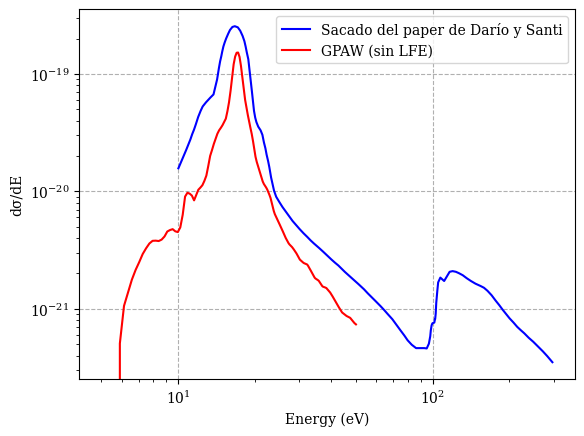

In [15]:
#plt.plot(omega_arr, dsig, label="GPAW (no LFE)", color='green')
plt.plot(df[df.columns[0]], df[df.columns[1]], label="Sacado del paper de Darío y Santi", color='blue') 
plt.plot(df_1[df_1.columns[0]], df_1[df_1.columns[1]], label="GPAW (sin LFE)", color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Energy (eV)")
plt.ylabel("dσ/dE")
plt.legend()
plt.grid(linestyle="--")

In [16]:
sigma_ref = df[df.columns[1]][df[df.columns[0]]<50]
e_ref = df[df.columns[0]][df[df.columns[0]]<50]
sigma_com = np.interp(e_ref,omega_arr, dsig)
comp = ((sigma_com-sigma_ref)/sigma_ref)*100


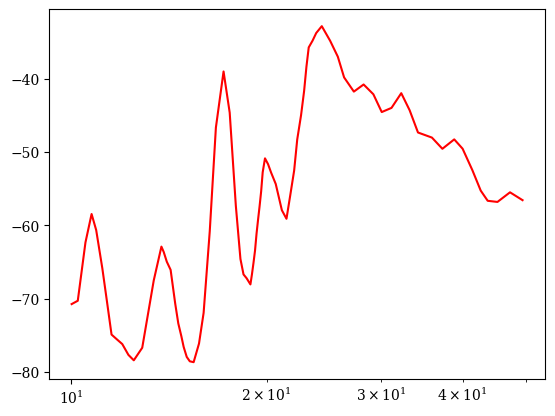

In [17]:
plt.plot(e_ref, comp, label="Comparación con el paper de Darío y Santi", color='red')
plt.xscale('log')
